# Sentiment Analysis of Drug Reviews

This notebook classifies patient reviews from Drugs.com as negative, neutral, or positive. It compares three TF-IDF models (Naive Bayes, Linear SVM, Logistic Regression) with a fine-tuned DistilBERT Transformer. Run on a T4 GPU runtime with Runtime, Run all.

## 1. Setup and Imports
Installs the libraries and downloads the NLTK resources used for tokenization, stop words, and lemmatization.

In [1]:
!pip install -q transformers datasets accelerate scikit-learn nltk kagglehub
import pandas as pd, numpy as np, re, html, nltk, os
import matplotlib.pyplot as plt
nltk.download('stopwords'); nltk.download('wordnet'); nltk.download('punkt'); nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 2. Data Loading
The Drug Reviews (Drugs.com) dataset is downloaded from its Kaggle mirror. Each row has a drug name, a condition, a free-text patient review, and a 1 to 10 rating. The training file has 161,297 reviews.

In [2]:
import kagglehub, os
path = kagglehub.dataset_download("jessicali9530/kuc-hackathon-winter-2018")
print(path)
print(os.listdir(path))

Using Colab cache for faster access to the 'kuc-hackathon-winter-2018' dataset.
/kaggle/input/kuc-hackathon-winter-2018
['drugsComTest_raw.csv', 'drugsComTrain_raw.csv']


In [3]:
df = pd.read_csv(os.path.join(path, 'drugsComTrain_raw.csv'))
print(df.shape)
df.head()

(161297, 7)


,uniqueID,drugName,condition,review,rating,date,usefulCount
0,206461,Valsartan,Left Ventricular Dysfunction,"""It has no side effect, I take it in combinati...",9,20-May-12,27
1,95260,Guanfacine,ADHD,"""My son is halfway through his fourth week of ...",8,27-Apr-10,192
2,92703,Lybrel,Birth Control,"""I used to take another oral contraceptive, wh...",5,14-Dec-09,17
3,138000,Ortho Evra,Birth Control,"""This is my first time using any form of birth...",8,3-Nov-15,10
4,35696,Buprenorphine / naloxone,Opiate Dependence,"""Suboxone has completely turned my life around...",9,27-Nov-16,37


## 3. Sentiment Labels
The dataset has no sentiment column, so labels are derived from the rating: 1 to 4 negative, 5 to 6 neutral, 7 to 10 positive. Missing values and duplicate reviews are removed first (112,329 reviews remain). The classes are imbalanced: 66.3% positive, 24.8% negative, 8.9% neutral, so macro-F1 is reported alongside accuracy.

In [4]:
# keep only the columns we need, drop rows with missing review or rating
df = df[['drugName', 'condition', 'review', 'rating']].dropna(subset=['review', 'rating'])
print("after dropping missing:", df.shape)

# drop duplicate reviews
df = df.drop_duplicates(subset='review')
print("after dropping duplicates:", df.shape)

# rating to sentiment label
def label(r):
    if r <= 4:
        return 'negative'
    elif r <= 6:
        return 'neutral'
    else:
        return 'positive'

df['sentiment'] = df['rating'].apply(label)

print(df['sentiment'].value_counts())
print(df['sentiment'].value_counts(normalize=True).round(3))

after dropping missing: (161297, 4)
after dropping duplicates: (112329, 4)
sentiment
positive    74497
negative    27839
neutral      9993
Name: count, dtype: int64
sentiment
positive    0.663
negative    0.248
neutral     0.089
Name: proportion, dtype: float64


## 4. Sampling and Summary Statistics
A stratified random sample of 30,000 reviews keeps the class proportions and makes DistilBERT training practical. Reviews average 84.5 words. The next cells plot the rating and sentiment distributions.

In [5]:
from sklearn.model_selection import train_test_split

# stratified sample of 30,000 reviews (keeps the same class proportions)
df_sample, _ = train_test_split(df, train_size=30000, stratify=df['sentiment'], random_state=42)
df_sample = df_sample.reset_index(drop=True)

print("sample size:", df_sample.shape[0])
print(df_sample['sentiment'].value_counts())
print(df_sample['sentiment'].value_counts(normalize=True).round(3))

# average review length in words
df_sample['word_count'] = df_sample['review'].str.split().str.len()
print("avg words per review:", round(df_sample['word_count'].mean(), 1))
print("median words per review:", df_sample['word_count'].median())

# top 10 conditions
print(df_sample['condition'].value_counts().head(10))

sample size: 30000
sentiment
positive    19896
negative     7435
neutral      2669
Name: count, dtype: int64
sentiment
positive    0.663
negative    0.248
neutral     0.089
Name: proportion, dtype: float64
avg words per review: 84.5
median words per review: 84.0
condition
Birth Control      4852
Depression         1664
Pain               1211
Anxiety            1151
Acne               1063
Insomnia            769
Bipolar Disorde     752
Weight Loss         710
Obesity             641
ADHD                591
Name: count, dtype: int64


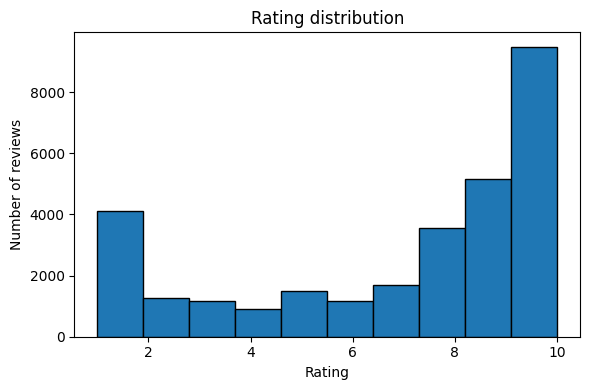

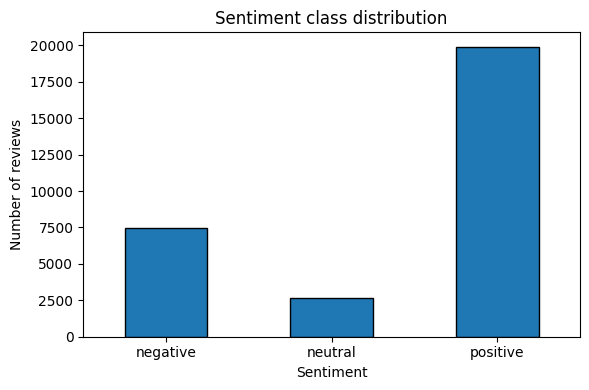

In [6]:
os.makedirs('figures', exist_ok=True)

plt.figure(figsize=(6, 4))
df_sample['rating'].plot(kind='hist', bins=10, edgecolor='black')
plt.xlabel('Rating'); plt.ylabel('Number of reviews'); plt.title('Rating distribution')
plt.tight_layout(); plt.savefig('figures/rating_distribution.png', dpi=200); plt.show()

plt.figure(figsize=(6, 4))
df_sample['sentiment'].value_counts().reindex(['negative', 'neutral', 'positive']).plot(kind='bar', edgecolor='black')
plt.xlabel('Sentiment'); plt.ylabel('Number of reviews'); plt.title('Sentiment class distribution')
plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig('figures/sentiment_distribution.png', dpi=200); plt.show()

## 5. Text Preprocessing
The cleaning function decodes HTML codes, lowercases text, removes URLs, digits, and punctuation, tokenizes, removes stop words, and lemmatizes. Negations (such as "not", "no", "never", "didn", "doesn") are kept in the text because they reverse sentiment, for example "no side effects" versus "not effective". The WordNet lemmatizer treats words as nouns by default, so plurals are reduced but verb forms are not.

In [7]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# stop words: keep negations because they flip sentiment
negations = {'no', 'nor', 'not', 'never', 'didn', 'don', 'doesn', 'isn', 'wasn',
             'weren', 'won', 'wouldn', 'couldn', 'shouldn', 'hadn', 'hasn',
             'haven', 'aren'}
stop_words = set(stopwords.words('english')) - negations
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = html.unescape(text)                  # fix &#039; and similar
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)   # remove URLs
    text = re.sub(r'[^a-z\s]', ' ', text)           # keep letters only (drops digits, punctuation)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)

# test on one review before running on everything
sample_review = df_sample['review'].iloc[0]
print("BEFORE:", sample_review)
print("AFTER: ", clean_text(sample_review))

BEFORE: "I&#039;ve found it to work great for depression. But the panic attacks are severe. I got 2 kidney stones was off citalopram. 3 weeks stayed off 1 month no panic attacks.  No hard heart beat but I get teary eyed."
AFTER:  found work great depression panic attack severe got kidney stone citalopram week stayed month no panic attack no hard heart beat get teary eyed


### Apply cleaning to all reviews
Cleaning shrinks the vocabulary from 76,978 to 23,250 distinct words and halves the average review length to 41.5 words. One review became empty and is removed before splitting.

In [8]:
import time
start = time.time()
df_sample['clean_review'] = df_sample['review'].apply(clean_text)
print("done in", round(time.time() - start, 1), "seconds")

# vocabulary size before and after cleaning (for the paper)
raw_vocab = set(w for r in df_sample['review'].str.lower() for w in r.split())
clean_vocab = set(w for r in df_sample['clean_review'] for w in r.split())
print("vocabulary before:", len(raw_vocab))
print("vocabulary after: ", len(clean_vocab))

# average length after cleaning
df_sample['clean_word_count'] = df_sample['clean_review'].str.split().str.len()
print("avg words per review after cleaning:", round(df_sample['clean_word_count'].mean(), 1))

# check for reviews that became empty
print("empty after cleaning:", (df_sample['clean_review'].str.strip() == '').sum())

done in 31.0 seconds
vocabulary before: 76978
vocabulary after:  23250
avg words per review after cleaning: 41.5
empty after cleaning: 1


## 6. Train/Test Split
One fixed stratified 80/20 split (random seed 42) gives 23,999 training and 6,000 test reviews. Every model uses the same split so the comparison is fair, and the test set is never used for tuning.

In [9]:
from sklearn.model_selection import train_test_split

# drop the review that became empty after cleaning
df_sample = df_sample[df_sample['clean_review'].str.strip() != ''].reset_index(drop=True)
print("rows after dropping empty:", df_sample.shape[0])

# one fixed 80/20 stratified split, reused for every model
train_df, test_df = train_test_split(
    df_sample, test_size=0.2, stratify=df_sample['sentiment'], random_state=42
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("train:", train_df.shape[0], "| test:", test_df.shape[0])
print(train_df['sentiment'].value_counts(normalize=True).round(3))
print(test_df['sentiment'].value_counts(normalize=True).round(3))

rows after dropping empty: 29999
train: 23999 | test: 6000
sentiment
positive    0.663
negative    0.248
neutral     0.089
Name: proportion, dtype: float64
sentiment
positive    0.663
negative    0.248
neutral     0.089
Name: proportion, dtype: float64


## 7. Feature Extraction: TF-IDF
TF-IDF converts each cleaned review into a numeric vector, weighting words that are frequent in a review but rare across reviews. Unigrams and bigrams are used (30,000 features, minimum document frequency 3). The vectorizer is fit on the training data only to avoid leaking information from the test set.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=30000)
X_train = tfidf.fit_transform(train_df['clean_review'])
X_test = tfidf.transform(test_df['clean_review'])
y_train = train_df['sentiment']
y_test = test_df['sentiment']

print("train matrix:", X_train.shape)
print("test matrix: ", X_test.shape)

train matrix: (23999, 30000)
test matrix:  (6000, 30000)


## 8. Model 1: Multinomial Naive Bayes
A fast probabilistic baseline that suits sparse word-count style features. The smoothing parameter alpha is tuned with 5-fold stratified cross-validation on macro-F1. Naive Bayes has no class weighting option, so it largely ignores the rare neutral class.

In [11]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
nb_grid = GridSearchCV(MultinomialNB(), {'alpha': [0.1, 0.5, 1.0]}, cv=cv, scoring='f1_macro')
nb_grid.fit(X_train, y_train)

print("best params:", nb_grid.best_params_)
print("best CV macro-F1:", round(nb_grid.best_score_, 3))

preds = {}   # we will store every model's test predictions here
preds['Naive Bayes'] = nb_grid.predict(X_test)
print(classification_report(y_test, preds['Naive Bayes'], digits=3))

best params: {'alpha': 0.1}
best CV macro-F1: 0.488
              precision    recall  f1-score   support

    negative      0.725     0.502     0.593      1487
     neutral      0.400     0.007     0.015       534
    positive      0.769     0.958     0.853      3979

    accuracy                          0.761      6000
   macro avg      0.631     0.489     0.487      6000
weighted avg      0.725     0.761     0.714      6000



## 9. Models 2 and 3: Linear SVM and Logistic Regression
Linear SVMs work well on high-dimensional sparse text. Logistic Regression is a linear model whose coefficients can be inspected later. Both use balanced class weights so neutral reviews count more during training, and the regularization strength C is tuned with 5-fold cross-validation on macro-F1.

In [13]:
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression

# Linear SVM
svm_grid = GridSearchCV(LinearSVC(class_weight='balanced', max_iter=5000, random_state=42),
                        {'C': [0.1, 1, 10]}, cv=cv, scoring='f1_macro')
svm_grid.fit(X_train, y_train)
print("SVM best params:", svm_grid.best_params_, "| CV macro-F1:", round(svm_grid.best_score_, 3))
preds['Linear SVM'] = svm_grid.predict(X_test)
print(classification_report(y_test, preds['Linear SVM'], digits=3))

# Logistic Regression
lr_grid = GridSearchCV(LogisticRegression(class_weight='balanced', max_iter=1000),
                       {'C': [0.1, 1, 10]}, cv=cv, scoring='f1_macro', n_jobs=-1)
lr_grid.fit(X_train, y_train)
print("LR best params:", lr_grid.best_params_, "| CV macro-F1:", round(lr_grid.best_score_, 3))
preds['Logistic Regression'] = lr_grid.predict(X_test)
print(classification_report(y_test, preds['Logistic Regression'], digits=3))

SVM best params: {'C': 1} | CV macro-F1: 0.569
              precision    recall  f1-score   support

    negative      0.652     0.673     0.662      1487
     neutral      0.205     0.146     0.171       534
    positive      0.846     0.869     0.857      3979

    accuracy                          0.756      6000
   macro avg      0.568     0.563     0.563      6000
weighted avg      0.741     0.756     0.748      6000

LR best params: {'C': 1} | CV macro-F1: 0.586
              precision    recall  f1-score   support

    negative      0.627     0.695     0.659      1487
     neutral      0.197     0.300     0.238       534
    positive      0.880     0.783     0.829      3979

    accuracy                          0.718      6000
   macro avg      0.568     0.593     0.575      6000
weighted avg      0.757     0.718     0.734      6000



In [14]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU available: True
Tesla T4


## 10. Model 4: DistilBERT
DistilBERT is a smaller, faster version of BERT that reads whole sentences in context. It is fine-tuned on the raw review text (HTML codes decoded) rather than the cleaned text, because its own tokenizer and context handling expect natural language. A 10% validation slice is taken from the training data only. Reviews are truncated to 256 tokens. The loss is weighted by class (negative 1.34, neutral 3.75, positive 0.50) to counter the imbalance.

In [15]:
from datasets import Dataset
from transformers import AutoTokenizer, DataCollatorWithPadding
from sklearn.utils.class_weight import compute_class_weight

label2id = {'negative': 0, 'neutral': 1, 'positive': 2}
id2label = {v: k for k, v in label2id.items()}

# validation slice comes out of train only; test set is untouched
tr_df, val_df = train_test_split(train_df, test_size=0.1, stratify=train_df['sentiment'], random_state=42)

def to_ds(d):
    # decode HTML codes (&#039; etc.) and strip the wrapping quotation marks
    return Dataset.from_dict({'text': d['review'].apply(lambda t: html.unescape(t).strip('"')).tolist(),
                              'label': d['sentiment'].map(label2id).tolist()})

tok = AutoTokenizer.from_pretrained('distilbert-base-uncased')
def tokenize(batch):
    return tok(batch['text'], truncation=True, max_length=256)

train_ds = to_ds(tr_df).map(tokenize, batched=True)
val_ds   = to_ds(val_df).map(tokenize, batched=True)
test_ds  = to_ds(test_df).map(tokenize, batched=True)

# class weights so the model does not ignore neutral (same idea as class_weight='balanced')
weights = compute_class_weight('balanced', classes=np.array([0, 1, 2]), y=np.array(train_ds['label']))
class_weights = torch.tensor(weights, dtype=torch.float)
print("class weights:", weights.round(2))
print(len(train_ds), len(val_ds), len(test_ds))

Map:   0%|          | 0/21599 [00:00<?, ? examples/s]

Map:   0%|          | 0/2400 [00:00<?, ? examples/s]

Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

class weights: [1.34 3.75 0.5 ]
21599 2400 6000


### Training and test predictions
The model is trained for 2 epochs with a learning rate of 2e-5, batch size 32, weight decay 0.01, and mixed precision, with seed 42. Predictions on the untouched test set are added to the shared predictions table and saved to all_preds.csv.

In [16]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

model = AutoModelForSequenceClassification.from_pretrained(
    'distilbert-base-uncased', num_labels=3, id2label=id2label, label2id=label2id)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    p = logits.argmax(axis=-1)
    return {'accuracy': accuracy_score(labels, p),
            'macro_f1': f1_score(labels, p, average='macro')}

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        loss = torch.nn.functional.cross_entropy(
            outputs.logits, labels, weight=class_weights.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

args = TrainingArguments(
    output_dir='distilbert_out', num_train_epochs=2,
    per_device_train_batch_size=32, per_device_eval_batch_size=64,
    learning_rate=2e-5, weight_decay=0.01, fp16=True, seed=42,
    eval_strategy='epoch', save_strategy='no', report_to='none')

trainer = WeightedTrainer(model=model, args=args, train_dataset=train_ds,
                          eval_dataset=val_ds, data_collator=DataCollatorWithPadding(tok),
                          compute_metrics=compute_metrics)
trainer.train()

# predict on the untouched test set and save everything
out = trainer.predict(test_ds)
preds['DistilBERT'] = [id2label[i] for i in out.predictions.argmax(axis=-1)]
print(classification_report(y_test, preds['DistilBERT'], digits=3))

pd.DataFrame(preds).to_csv('all_preds.csv', index=False)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.830310,0.752187,0.789583,0.650313
2,0.668518,0.741980,0.777917,0.661141


              precision    recall  f1-score   support

    negative      0.766     0.746     0.756      1487
     neutral      0.239     0.500     0.323       534
    positive      0.941     0.813     0.872      3979

    accuracy                          0.768      6000
   macro avg      0.649     0.686     0.651      6000
weighted avg      0.836     0.768     0.795      6000



## 11. Model Evaluation
All four models are scored on the same 6,000 test reviews: accuracy, macro-averaged precision, recall, and F1, plus F1 for each class. The confusion matrices are normalized by true class, so each row shows what share of that class was predicted as each label. Accuracy differs little between models; macro-F1 and neutral-class performance separate them.

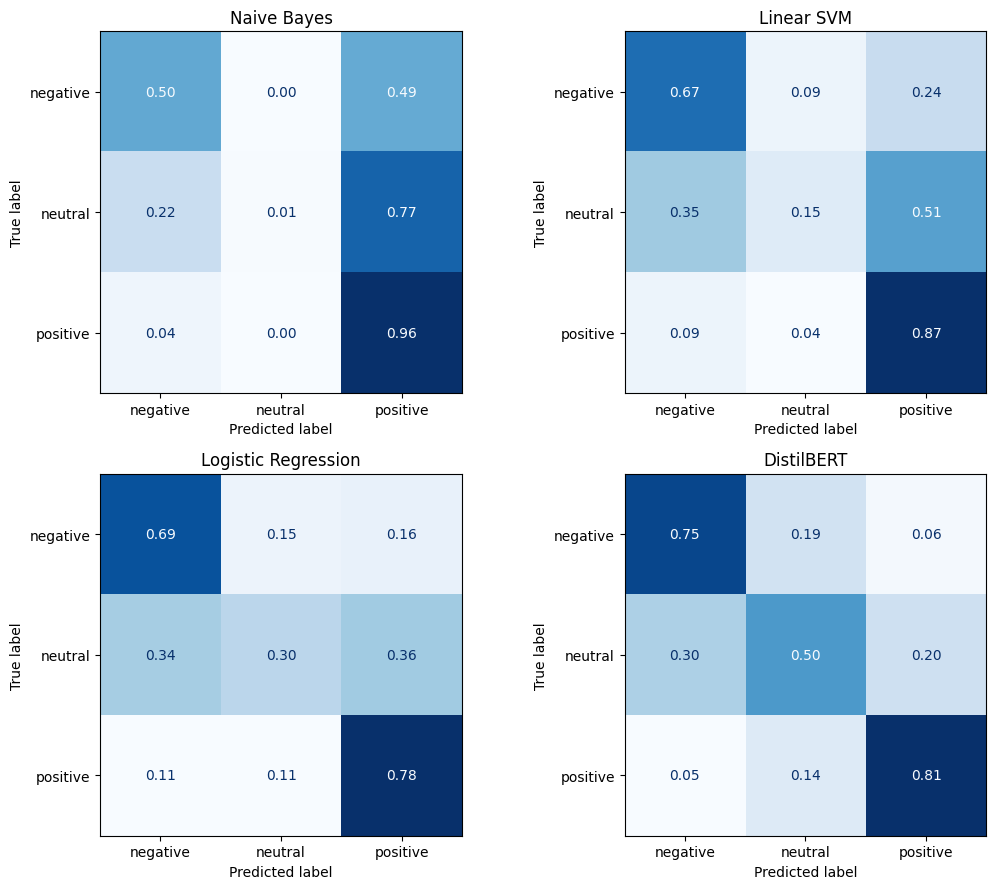

,model,accuracy,macro_precision,macro_recall,macro_f1,f1_negative,f1_neutral,f1_positive
0,Naive Bayes,0.761,0.631,0.489,0.487,0.593,0.015,0.853
1,Linear SVM,0.756,0.568,0.563,0.563,0.662,0.171,0.857
2,Logistic Regression,0.718,0.568,0.593,0.575,0.659,0.238,0.829
3,DistilBERT,0.768,0.649,0.686,0.651,0.756,0.323,0.872


In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support

os.makedirs('results', exist_ok=True)
os.makedirs('figures', exist_ok=True)
order = ['negative', 'neutral', 'positive']

rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, p, labels=order, normalize='true')   # rows sum to 1
    ConfusionMatrixDisplay(cm, display_labels=order).plot(ax=ax, colorbar=False, values_format='.2f', cmap='Blues')
    ax.set_title(name)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, p, average='macro')
    per_class = f1_score(y_test, p, average=None, labels=order)
    rows.append({'model': name, 'accuracy': accuracy_score(y_test, p),
                 'macro_precision': prec, 'macro_recall': rec, 'macro_f1': f1,
                 'f1_negative': per_class[0], 'f1_neutral': per_class[1], 'f1_positive': per_class[2]})
plt.tight_layout()
plt.savefig('figures/confusion_matrices.png', dpi=200)
plt.show()

results_df = pd.DataFrame(rows).round(3)
results_df.to_csv('results/metrics.csv', index=False)
results_df


## 12. Interpretation
### Words that drive each prediction
The largest Logistic Regression coefficients show which words and phrases push a review toward each class. Negative and positive classes are driven by clear evaluative language and negation phrases; neutral is driven by hedging words such as "however", "yet", and "not sure".

In [18]:
lr_best = lr_grid.best_estimator_
terms = np.array(tfidf.get_feature_names_out())
for i, cls in enumerate(lr_best.classes_):
    top = np.argsort(lr_best.coef_[i])[-15:][::-1]
    print(cls.upper(), ':', ', '.join(terms[top]), '\n')

NEGATIVE : worse, worst, not recommend, never, not worth, not, nothing, horrible, no relief, terrible, not work, removed, doesn work, disappointed, please 

NEUTRAL : however, hope, yet, update, notice, considering, noticed, not sure, vicodin, although, hoping, potassium, like crazy, lidocaine, getting 

POSITIVE : love, great, miracle, happy, amazing, gone, life, year, best, saved, no side, would recommend, recommend, free, happier 



### Sentiment by condition
Share of negative, neutral, and positive reviews among the ten most common conditions, using the rating-based labels. Birth Control has the highest negative share (35.4%) and Weight Loss the lowest (13.0%). Small differences between the middle conditions should not be over-read.

In [19]:
top_conds = df_sample['condition'].value_counts().head(10).index
sub = df_sample[df_sample['condition'].isin(top_conds)]
tab = pd.crosstab(sub['condition'], sub['sentiment'], normalize='index').round(3)
tab['n_reviews'] = sub['condition'].value_counts()
tab = tab.sort_values('negative', ascending=False)
tab.to_csv('results/sentiment_by_condition.csv')
tab

sentiment,negative,neutral,positive,n_reviews
condition,,,,
Birth Control,0.354,0.127,0.519,4852
Insomnia,0.254,0.075,0.671,769
Depression,0.234,0.094,0.672,1664
Bipolar Disorde,0.219,0.059,0.722,752
ADHD,0.212,0.088,0.701,591
Acne,0.202,0.076,0.722,1063
Pain,0.177,0.069,0.755,1211
Anxiety,0.156,0.071,0.772,1151
Obesity,0.156,0.084,0.760,641


### Error analysis
A random sample of DistilBERT mistakes. Most are predicted as neutral. Common causes are mixed reviews that describe both benefits and side effects, long narratives where the verdict comes late, and ratings that do not match the tone of the text (label noise).

In [20]:
err = test_df.copy()
err['pred'] = preds['DistilBERT']
wrong = err[err['sentiment'] != err['pred']]
print("DistilBERT errors:", len(wrong), "of", len(err))
for _, r in wrong.sample(10, random_state=1).iterrows():
    print(f"TRUE={r.sentiment} | PRED={r.pred} | RATING={r.rating}")
    print(r.review[:300], "\n")

DistilBERT errors: 1390 of 6000
TRUE=positive | PRED=neutral | RATING=7
"I started using this birth control after a previous one since it was too strong (on it for 4 months).  I have been using this for 7 months and I have since gained 30 lbs.  I eat very healthy and exercise 5 days a week, as well as live in a city so I walk up to 8 miles a day.  Plus I am in training  

TRUE=neutral | PRED=negative | RATING=5
"My father-in-law took this medication and it gave him alot of extra pyramidal movements and Tardive Dyskinesia." 

TRUE=positive | PRED=neutral | RATING=8
"I have been using this for about three weeks now. There was a big initial &quot;boost&quot; in my energy levels, mood, work performance and all across the board things seemed to get better, and depression seemed to lift quite a bit. It does not stick for me if I delay putting on my shirt for 10-15  

TRUE=positive | PRED=neutral | RATING=7
"let me say I am 20, started off with tiny blackheads all over my head and a couple bi

## 13. Summary
DistilBERT achieves the best macro-F1 (0.651), followed by Logistic Regression (0.575), Linear SVM (0.563), and Naive Bayes (0.487). Neutral is the hardest class for every model. Limitations include sentiment labels derived from ratings, a single DistilBERT training run, and self-selected reviewers. See the README for how to reproduce the results.